# Zero-Order Hold: Multiple Shooting

Solve the Cartesian two-body TOPS `P0` benchmark with multiple shooting, following the first example in [Zero-Order Hold I](./udp_zoh_point2point.ipynb). The interior states are initialized by propagating from the fixed endpoints.

In [1]:
import pykep as pk
import numpy as np
import pygmo as pg
import pygmo_plugins_nonfree as ppnf

from matplotlib import pyplot as plt

In [16]:
ipopt = pg.ipopt()
ipopt.set_integer_options({"max_iter": 2000})
ipopt.set_numeric_options({"tol": 1e-10})
ipopt.set_string_options({"sb": "yes"})

path_to_snopt72 = "/opt/lib/libsnopt7_c.so"
snopt = ppnf.snopt7(library=path_to_snopt72, minor_version=2, screen_output=True)
snopt.set_integer_option("Major iterations limit", 2000)
snopt.set_integer_option("Iterations limit", 20000)
snopt.set_numeric_option("Major optimality tolerance", 1e-3)
snopt.set_numeric_option("Major feasibility tolerance", 1e-12)
#snopt.set_integer_option("Hessian full memory", 1);


algo = pg.algorithm(snopt)

In [17]:
prob_name = "P0"
udp = pk.trajopt.gym.tops_twobody(prob_name, nseg=10, time_encoding="softmax", ms=True)
print(udp.extra_info)

prob = pg.problem(udp)
prob.c_tol = 1e-7
print("Variables:", prob.get_nx(), "Equalities:", prob.get_nec(), "Inequalities:", prob.get_nic())

Mildly-elliptic to mildly-elliptic transfer (e_s~0.201, e_f~0.210) in fixed tof -> T=0.22N, Isp=3000s
Variables: 115 Equalities: 70 Inequalities: 10


Initialize the internal states of each population member from its controls and time grid. A propagated state outside the node bounds raises `ValueError`. A finite defect or a feasible fitness alone does not establish that every segment propagation succeeded.

In [21]:
pop = pg.population(prob, 1)
for i, x in enumerate(pop.get_x()):
    pop.set_x(i, udp.guess_internal_states(x, ballistic=True))

Compare the analytical gradient with finite differences. `prob.gradient_sparsity()` supplies the coordinates for either a sparse or dense gradient.

In [22]:
x = pop.champion_x
pattern = prob.gradient_sparsity()
jacobian = np.zeros((prob.get_nf(), prob.get_nx()))
jacobian[pattern[:, 0], pattern[:, 1]] = prob.gradient(x)
numerical = pg.estimate_gradient_h(prob.fitness, x, dx=1e-8).reshape(jacobian.shape)
grad_err = numerical - jacobian
grad_err.min(), grad_err.max()

(-1.4260215441125323e-07, 1.6361330842235011e-07)

In [23]:
pop = algo.evolve(pop)
print("Feasible:", prob.feasibility_f(pop.champion_f))
print("Objective:", pop.champion_f[0])
print("Final mass:", pop.champion_x[0] * udp.MASS)
print("Final tof:", pop.champion_x[4 * udp.nseg + 1] * udp.TIME)

   SNOPT  C interface  2.0.0   
 S N O P T  7.2-4    (Jun 2006)
 
 SNMEMA EXIT 100 -- finished successfully
 SNMEMA INFO 104 -- memory requirements estimated
 

 Nonlinear constraints      80     Linear constraints       0
 Nonlinear variables       115     Linear variables         0
 Jacobian  variables       115     Objective variables      1
 Total constraints          80     Total variables        115
 

 
 The user has defined    1970   out of    1970   first  derivatives
 

 Major Minors     Step   nCon Feasible  Optimal  MeritFunction    nS Penalty
     0     88               1  9.7E-02  1.1E-02 -9.5092941E-01    37           r
     1     15  1.0E+00      2  6.4E-02  7.6E-03 -8.4543484E-01    31 7.8E-01 n r
     2      6  1.0E+00      4  5.2E-02  1.6E-02 -9.5924136E-01    32 1.2E+00 sM
     3      7  1.0E+00      5  1.4E-02  4.5E-03 -8.9708452E-01    34 1.8E+00
     4      2  1.0E+00      7  9.0E-04  4.6E-02 -9.1130740E-01    33 1.8E+00  M
     5      1  1.0E+00      8  1.5E-03 

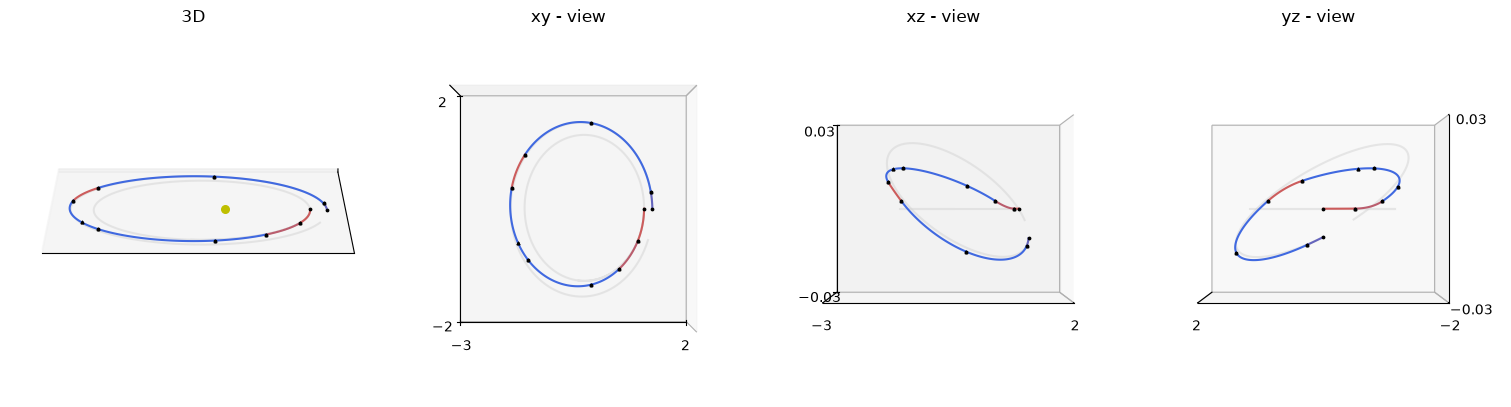

In [10]:
axes = udp.plot(pop.champion_x, N=100, mark_segments=True, s=3, c="k")

<Axes: xlabel='time grid', ylabel='throttle value (nd)'>

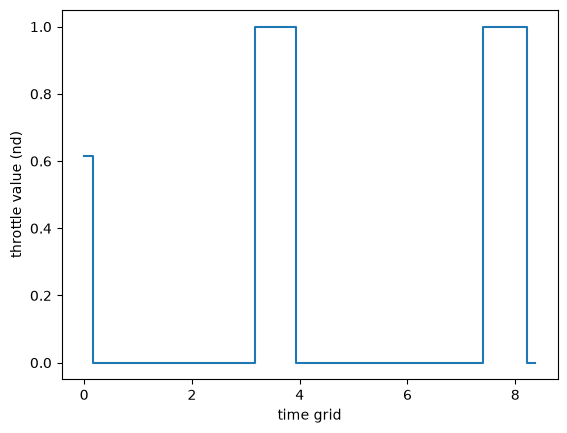

In [57]:
udp.plot_throttle(pop.champion_x)